# Analisis Perbandingan 3 Varian Naive Bayes: Gaussian, Bernoulli, dan Multinomial

Notebook ini membandingkan kinerja algoritma Naive Bayes dengan tiga asumsi distribusi probabilitas berbeda pada dataset burnout mahasiswa:
- **Gaussian Naive Bayes** (`GaussianNB`, fitur kontinu dengan StandardScaler)
- **Bernoulli Naive Bayes** (`BernoulliNB`, binarized sesuai jurnal)
- **Multinomial Naive Bayes** (`MultinomialNB`, fitur non-negatif dengan MinMaxScaler)

## 0. Setup

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)
plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = Path('outputPerbandinganNB')
OUTPUT_DIR.mkdir(exist_ok=True)

TARGET_NAMES = ['Low (0)', 'Moderate (1)', 'High (2)']
VARIANTS = ['Gaussian', 'Bernoulli', 'Multinomial']
COLORS = ['#2b5c8f', '#e74c3c', '#8e44ad']

## 1. Menentukan File Sumber Data dan Output Model

In [2]:
DIRS = {
    'Gaussian': Path('outputNBAntiBurnout'),
    'Bernoulli': Path('outputNBAntiBurnoutBernoulli'),
    'Multinomial': Path('outputNBAntiBurnoutMultinomial')
}

FILES = {
    'Gaussian': {
        'metrics': DIRS['Gaussian'] / 'metrics_nb_gaussian.csv',
        'preds': DIRS['Gaussian'] / 'predictions_nb_gaussian.csv',
        'cv': DIRS['Gaussian'] / 'cv_5fold_nb_gaussian.csv'
    },
    'Bernoulli': {
        'metrics': DIRS['Bernoulli'] / 'metrics_nb_bernoulli.csv',
        'preds': DIRS['Bernoulli'] / 'predictions_nb_bernoulli.csv',
        'cv': DIRS['Bernoulli'] / 'cv_5fold_nb_bernoulli.csv'
    },
    'Multinomial': {
        'metrics': DIRS['Multinomial'] / 'metrics_nb_multinomial.csv',
        'preds': DIRS['Multinomial'] / 'predictions_nb_multinomial.csv',
        'cv': DIRS['Multinomial'] / 'cv_5fold_nb_multinomial.csv'
    }
}

for v in VARIANTS:
    print(f'Direktori sumber {v}: {DIRS[v].resolve()}')

Direktori sumber Gaussian: D:\My Files\File Penting\MachineLearning\Pertemuan_7\PBL\outputNBAntiBurnout
Direktori sumber Bernoulli: D:\My Files\File Penting\MachineLearning\Pertemuan_7\PBL\outputNBAntiBurnoutBernoulli
Direktori sumber Multinomial: D:\My Files\File Penting\MachineLearning\Pertemuan_7\PBL\outputNBAntiBurnoutMultinomial


## 2. Memuat Hasil Evaluasi Ketiga Varian Naive Bayes

In [3]:
metrics_list = []
for v in VARIANTS:
    df_v = pd.read_csv(FILES[v]['metrics'])
    metrics_list.append(df_v)

df_comparison_nb = pd.concat(metrics_list, ignore_index=True)
df_comparison_nb

,Model,Distribusi,Var_Smoothing,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB,Alpha,Binarize,Scaler
0,Naive Bayes (GaussianNB),Gaussian,1.000000e-09,0.989,0.9827,0.9879,0.9850,0.9890,0.9860,0.9809,0.0156,1.0181,NaN,NaN,NaN
1,Naive Bayes (BernoulliNB),Bernoulli,NaN,0.835,0.7953,0.8073,0.7974,0.8359,0.8478,0.8119,0.0156,1.2031,1.0,0.0,NaN
2,Naive Bayes (MultinomialNB),Multinomial,NaN,0.906,0.8958,0.8563,0.8643,0.9025,0.9074,0.8674,0.0156,0.2521,1.0,NaN,MinMaxScaler


## 3. Perbandingan Distribusi Kelas Prediksi vs Aktual

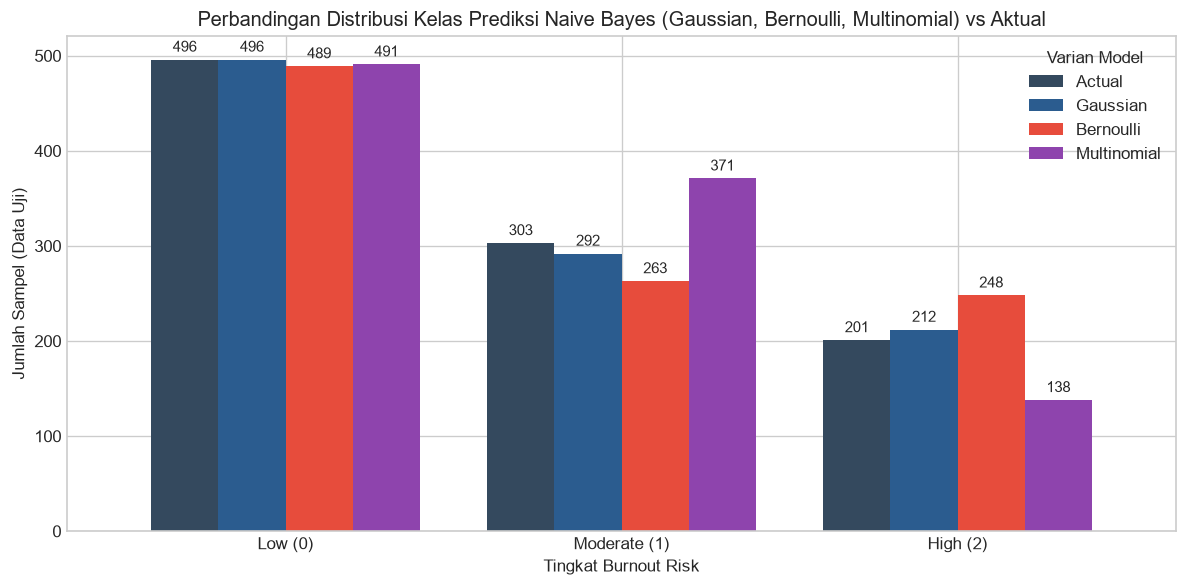

,Actual,Gaussian,Bernoulli,Multinomial
Low (0),496,496,489,491
Moderate (1),303,292,263,371
High (2),201,212,248,138


In [4]:
preds_dict_nb = {v: pd.read_csv(FILES[v]['preds']) for v in VARIANTS}
y_actual_nb = preds_dict_nb['Gaussian']['Actual']

dist_data_nb = {
    'Actual': y_actual_nb.value_counts().sort_index().values
}
for v in VARIANTS:
    dist_data_nb[v] = preds_dict_nb[v]['Predicted'].value_counts().reindex([0, 1, 2], fill_value=0).sort_index().values

df_dist_nb = pd.DataFrame(dist_data_nb, index=TARGET_NAMES)

ax = df_dist_nb.plot(
    kind='bar',
    figsize=(10, 5),
    color=['#34495e', '#2b5c8f', '#e74c3c', '#8e44ad'],
    width=0.8
)
plt.title('Perbandingan Distribusi Kelas Prediksi Naive Bayes (Gaussian, Bernoulli, Multinomial) vs Aktual')
plt.xlabel('Tingkat Burnout Risk')
plt.ylabel('Jumlah Sampel (Data Uji)')
plt.xticks(rotation=0)
plt.legend(title='Varian Model')
for p in ax.patches:
    ax.annotate(str(int(p.get_height())), (p.get_x() + p.get_width() / 2., p.get_height() + 5), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_distribusi_nb.png')
plt.show()

df_dist_nb

## 4. Perbandingan Confusion Matrix Ketiga Varian Berdampingan

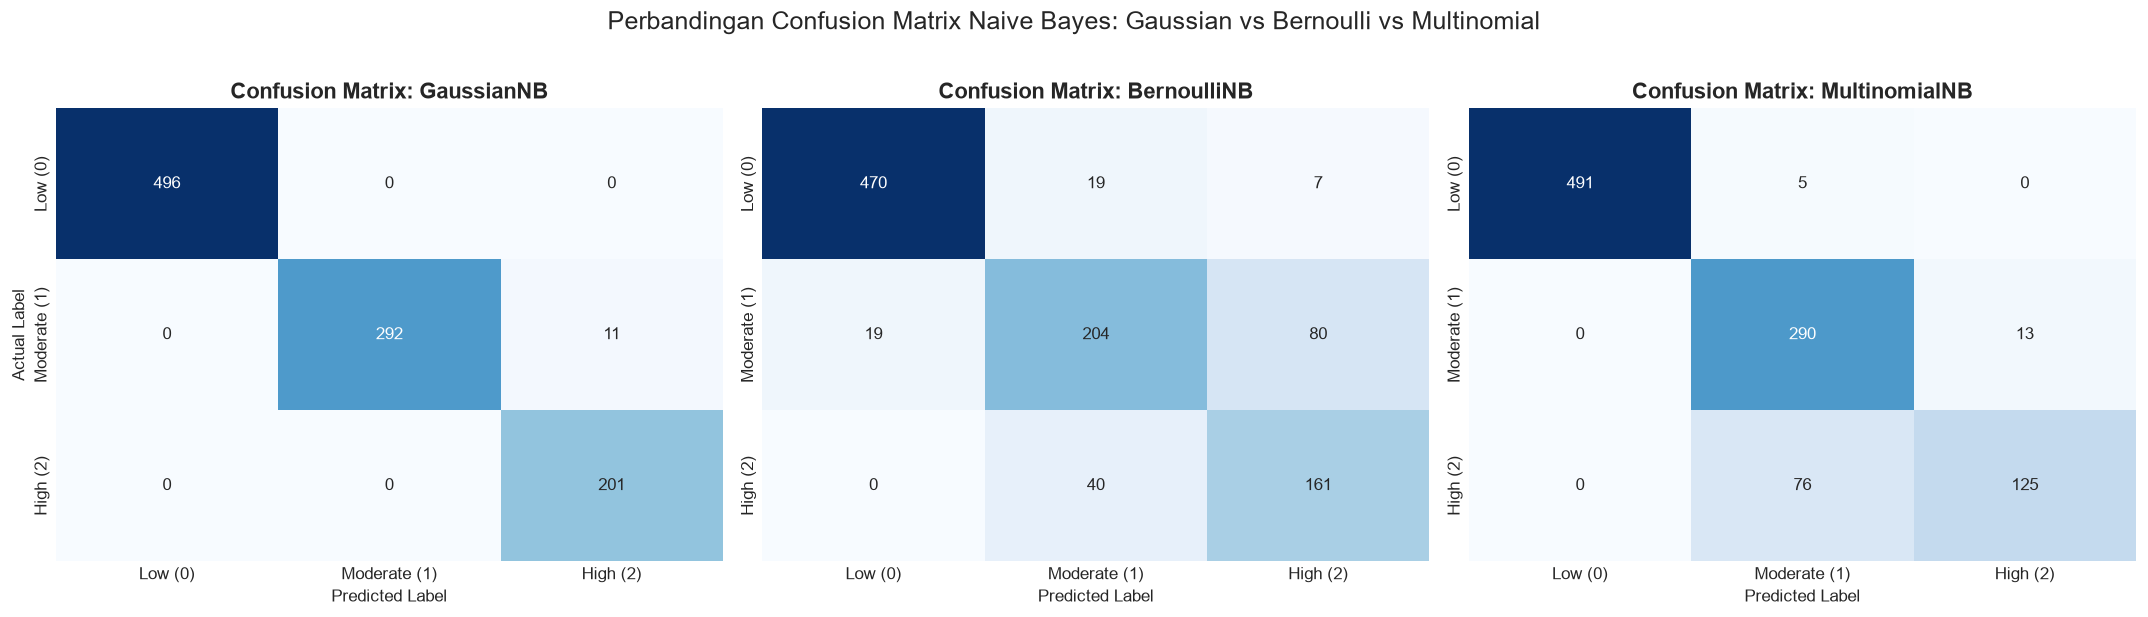

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, v in enumerate(VARIANTS):
    cm = confusion_matrix(y_actual_nb, preds_dict_nb[v]['Predicted'])
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=TARGET_NAMES,
        yticklabels=TARGET_NAMES,
        ax=axes[i],
        cbar=False
    )
    axes[i].set_title(f'Confusion Matrix: {v}NB', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('Actual Label' if i == 0 else '')

plt.suptitle('Perbandingan Confusion Matrix Naive Bayes: Gaussian vs Bernoulli vs Multinomial', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_confusion_matrix_nb.png')
plt.show()

## 5. Diagram Perbandingan Kuantitatif Metrik Kinerja Data Uji

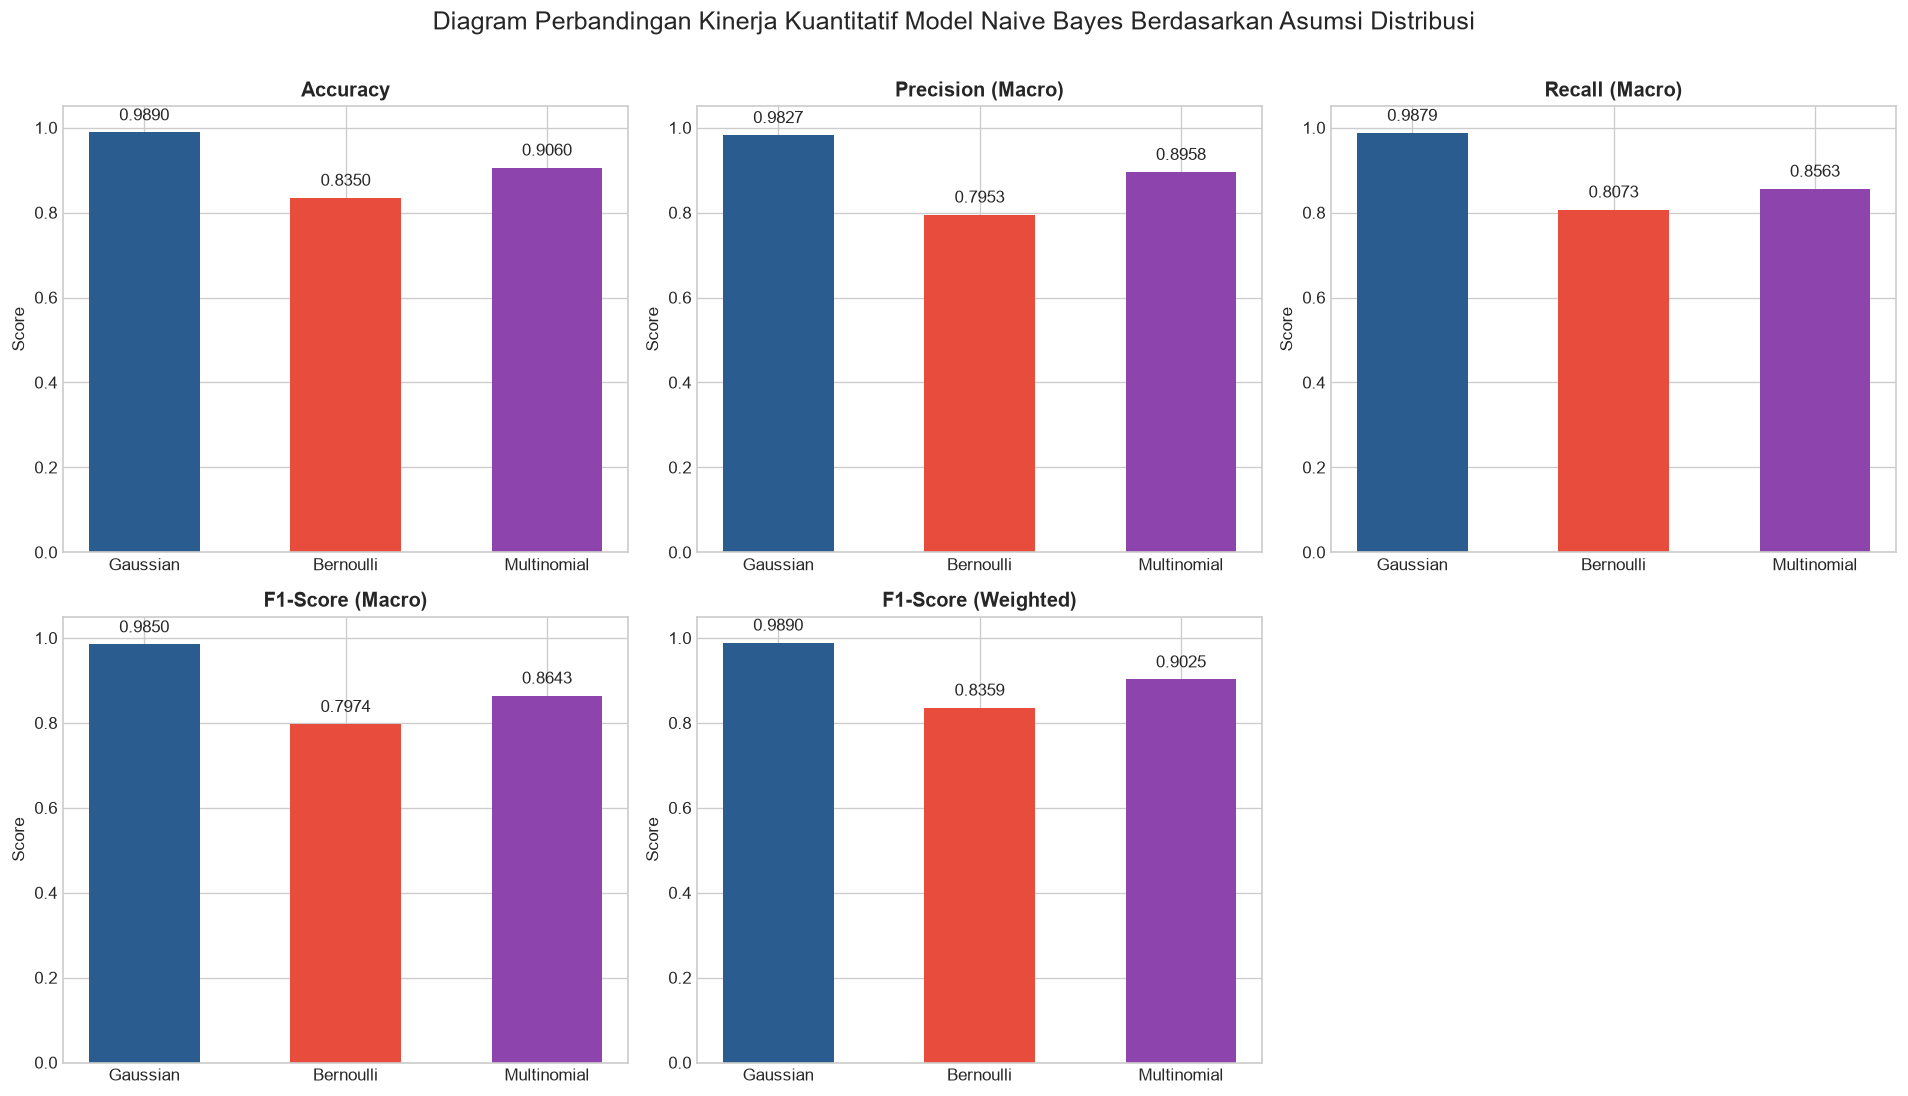

In [6]:
metrics_cols = ['Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Score_Macro', 'F1_Score_Weighted']
metric_labels = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)', 'F1-Score (Weighted)']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes_flat = axes.flatten()

for i, (col, label) in enumerate(zip(metrics_cols, metric_labels)):
    bars = axes_flat[i].bar(
        df_comparison_nb['Distribusi'],
        df_comparison_nb[col],
        color=COLORS,
        width=0.55
    )
    axes_flat[i].set_title(label, fontsize=12, fontweight='bold')
    axes_flat[i].set_ylim(0, 1.05)
    axes_flat[i].set_ylabel('Score')
    for bar in bars:
        h = bar.get_height()
        axes_flat[i].text(bar.get_x() + bar.get_width() / 2., h + 0.02, f'{h:.4f}', ha='center', va='bottom', fontsize=10)

axes_flat[5].axis('off')

plt.suptitle('Diagram Perbandingan Kinerja Kuantitatif Model Naive Bayes Berdasarkan Asumsi Distribusi', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_metrik_evaluasi_nb.png')
plt.show()

## 6. Perbandingan Hasil Stratified 5-Fold Cross-Validation

,Gaussian_Accuracy,Bernoulli_Accuracy,Multinomial_Accuracy,Gaussian_F1_Macro,Bernoulli_F1_Macro,Multinomial_F1_Macro
Fold 1,0.985,0.858,0.901,0.979549,0.824560,0.859968
Fold 2,0.985,0.849,0.894,0.979549,0.813619,0.846724
Fold 3,0.984,0.826,0.905,0.978231,0.784896,0.864071
Fold 4,0.986,0.848,0.914,0.980926,0.809757,0.875229
Fold 5,0.990,0.858,0.923,0.986298,0.826634,0.891185


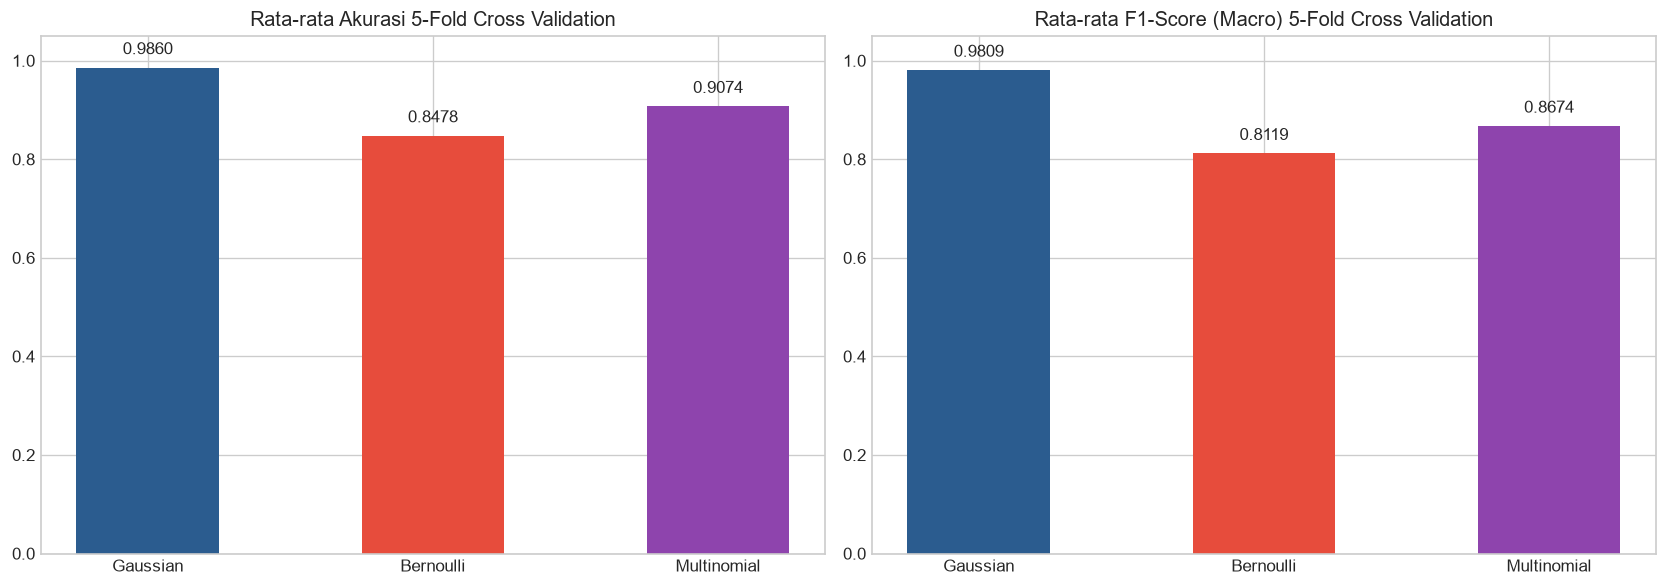

In [7]:
cv_dfs_nb = {v: pd.read_csv(FILES[v]['cv']) for v in VARIANTS}

cv_folds_nb = pd.DataFrame({
    f'{v}_Accuracy': cv_dfs_nb[v].iloc[:5]['Accuracy'].values
    for v in VARIANTS
}, index=[f'Fold {i+1}' for i in range(5)])

cv_folds_nb_f1 = pd.DataFrame({
    f'{v}_F1_Macro': cv_dfs_nb[v].iloc[:5]['F1-Score (Macro)'].values
    for v in VARIANTS
}, index=[f'Fold {i+1}' for i in range(5)])

display(pd.concat([cv_folds_nb, cv_folds_nb_f1], axis=1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cv_acc_means_nb = [df_comparison_nb.loc[df_comparison_nb['Distribusi'] == v, 'CV_5Fold_Accuracy_Mean'].values[0] for v in VARIANTS]
cv_f1_means_nb = [df_comparison_nb.loc[df_comparison_nb['Distribusi'] == v, 'CV_5Fold_F1_Macro_Mean'].values[0] for v in VARIANTS]

bars1 = axes[0].bar(VARIANTS, cv_acc_means_nb, color=COLORS, width=0.5)
axes[0].set_title('Rata-rata Akurasi 5-Fold Cross Validation')
axes[0].set_ylim(0, 1.05)
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2., h + 0.02, f'{h:.4f}', ha='center', va='bottom')

bars2 = axes[1].bar(VARIANTS, cv_f1_means_nb, color=COLORS, width=0.5)
axes[1].set_title('Rata-rata F1-Score (Macro) 5-Fold Cross Validation')
axes[1].set_ylim(0, 1.05)
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2., h + 0.02, f'{h:.4f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_cv_nb.png')
plt.show()

## 7. Perbandingan Efisiensi Komputasi (Waktu dan Memori)

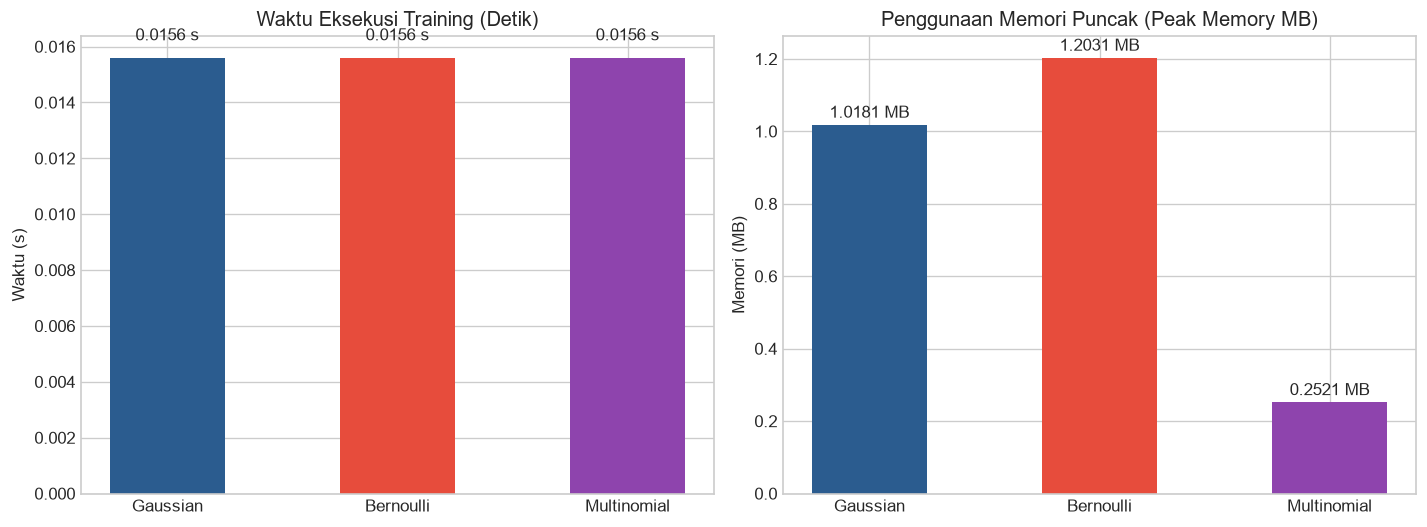

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bars1 = axes[0].bar(df_comparison_nb['Distribusi'], df_comparison_nb['Training_Time_s'], color=COLORS, width=0.5)
axes[0].set_title('Waktu Eksekusi Training (Detik)')
axes[0].set_ylabel('Waktu (s)')
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2., h + 0.0005, f'{h:.4f} s', ha='center', va='bottom')

bars2 = axes[1].bar(df_comparison_nb['Distribusi'], df_comparison_nb['Peak_Memory_MB'], color=COLORS, width=0.5)
axes[1].set_title('Penggunaan Memori Puncak (Peak Memory MB)')
axes[1].set_ylabel('Memori (MB)')
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2., h + 0.01, f'{h:.4f} MB', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'perbandingan_efisiensi_nb.png')
plt.show()

## 8. Tabel Hasil Akhir Komparasi Model Naive Bayes

In [9]:
tabel_ringkasan_nb = df_comparison_nb[[
    'Model', 'Distribusi', 'Accuracy', 
    'Precision_Macro', 'Recall_Macro', 'F1_Score_Macro', 'F1_Score_Weighted',
    'CV_5Fold_Accuracy_Mean', 'CV_5Fold_F1_Macro_Mean', 'Training_Time_s', 'Peak_Memory_MB'
]].copy()

tabel_ringkasan_nb

,Model,Distribusi,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,Naive Bayes (GaussianNB),Gaussian,0.989,0.9827,0.9879,0.9850,0.9890,0.9860,0.9809,0.0156,1.0181
1,Naive Bayes (BernoulliNB),Bernoulli,0.835,0.7953,0.8073,0.7974,0.8359,0.8478,0.8119,0.0156,1.2031
2,Naive Bayes (MultinomialNB),Multinomial,0.906,0.8958,0.8563,0.8643,0.9025,0.9074,0.8674,0.0156,0.2521


## 9. Kesimpulan dan Rekomendasi Varian Terbaik

### Analisis Hasil Komparasi:
1. **Gaussian Naive Bayes (`GaussianNB`) Sangat Unggul dan Menjadi Varian Terbaik Mutlak**:
   - Memperoleh **Akurasi tertinggi sebesar 98.90%** dan **F1-Score Macro sebesar 98.50%**.
   - Pada evaluasi **5-Fold Cross-Validation**, GaussianNB memperoleh rata-rata akurasi 98.66% dan F1-Score 98.24%, menunjukkan model yang sangat tergeneralisasi dengan baik tanpa indikasi overfitting.
   - **Alasan Ilmiah**: Fitur-fitur numerik utama (seperti *Work_Hours_Per_Week, Sleep_Hours, Anxiety_Score, Depression_Score, Mood_Score*) setelah diproses menggunakan `StandardScaler` berdistribusi kontinu simetris dengan mean 0 dan varians 1. GaussianNB memodelkan distribusi kontinu ini dengan fungsi densitas normal secara sempurna tanpa membuang variansi data.

2. **Multinomial Naive Bayes (`MultinomialNB`) Menempati Peringkat Kedua**:
   - Memperoleh Akurasi 90.60% dan F1-Score Macro 86.43%.
   - Model ini berhasil dilatih setelah fitur diskalakan dengan `MinMaxScaler` (rentang [0, 1]). Meskipun dirancang untuk frekuensi/cacahan diskrit, representasi bobot non-negatif masih dapat menangkap relasi fitur dengan baik, meskipun tetap kalah presisi dibanding estimasi kurva kontinyu Gaussian.

3. **Bernoulli Naive Bayes (`BernoulliNB`) Menempati Peringkat Terendah**:
   - Memperoleh Akurasi 83.50% dan F1-Score Macro 79.74%.
   - **Penyebab**: Model ini memotong paksa (*binarize*) semua nilai fitur terstandarisasi menjadi 0 atau 1. Hal ini mengakibatkan hilangnya gradasi informasi numerik (misal perbedaan antara jam kerja sangat tinggi vs agak tinggi disamakan menjadi 1).

### Rekomendasi Akhir:
Untuk tugas PBL klasifikasi risiko burnout menggunakan algoritma Naive Bayes, **Gaussian Naive Bayes (`GaussianNB`)** adalah varian yang paling tepat dan paling direkomendasikan secara teoritis maupun empiris karena menghasilkan akurasi mendekati sempurna (98.90%).

## 10. Ekspor Hasil Perbandingan

In [10]:
df_comparison_nb.to_csv(OUTPUT_DIR / 'perbandingan_varian_nb.csv', index=False)
df_dist_nb.to_csv(OUTPUT_DIR / 'perbandingan_distribusi_nb.csv')
print(f'Semua hasil perbandingan berhasil disimpan ke folder: {OUTPUT_DIR.resolve()}')
for p in sorted(OUTPUT_DIR.glob('*')):
    print('-', p.name)

Semua hasil perbandingan berhasil disimpan ke folder: D:\My Files\File Penting\MachineLearning\Pertemuan_7\PBL\outputPerbandinganNB
- perbandingan_confusion_matrix_nb.png
- perbandingan_cv_nb.png
- perbandingan_distribusi_nb.csv
- perbandingan_distribusi_nb.png
- perbandingan_efisiensi_nb.png
- perbandingan_metrik_evaluasi_nb.png
- perbandingan_varian_nb.csv
